# Анализ строительных компаний (ОКВЭД 41.20)

Исходный Excel весил 86 МБ и тяжело открывался. Поэтому я сначала случайно отобрал 10 000 строк, а уже потом применил фильтры. Оставил только малые и средние юридические лица с ОКВЭД 41.20. После фильтрации осталось 149 компаний: 136 малых и 13 средних. Выборка небольшая, потому что отбор шёл из части реестра.

В ГИР БО нашлось 655 годовых отчётов за 2021-2025 годы по 147 компаниям. В блокноте использую сохранённую выгрузку. Для повторного сбора есть скрипт на Selenium в папке `fns_collection`.

[Реестр МСП](https://rmsp.nalog.ru/) | [ГИР БО ФНС](https://bo.nalog.gov.ru/)

In [1]:
import re
import unicodedata
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import pandas as pd
import plotly.express as px
import requests
from IPython.display import display

companies = pd.read_csv('companies.csv', dtype={'inn': str, 'okved': str}).fillna('')
assert len(companies) == 149 and companies.inn.is_unique
assert companies.okved.eq('41.20').all()
display(companies.groupby('category').size().rename('Компаний').to_frame())

CACHE = Path('cache')
CACHE.mkdir(exist_ok=True)
RESULTS = Path('results')
RESULTS.mkdir(exist_ok=True)
YEARS = range(2019, 2026)

,Компаний
category,
Малое предприятие,136
Среднее предприятие,13


## Расчёт EBITA

Из годовых форм беру выручку (2110), чистую прибыль (2400), прибыль до налога (2300) и проценты (2320 и 2330). Все суммы в тысячах рублей.

`EBIT = прибыль до налога + |проценты к уплате| - проценты к получению`

`EBITA = EBIT + амортизация нематериальных активов за год`

Амортизацию НМА беру из пояснений к отчётам. Если сумма не указана или её нельзя прочитать, оставляю пропуск. Ноль ставлю только там, где он подтверждён пояснениями.

[Статья из задания](https://blog.sf.education/ebita-v-finansah-prostym-yazykom/)

In [2]:
status = pd.read_csv('data/collection_status.csv', dtype={'inn': str})
finance = pd.read_csv('data/financials.csv', dtype={'inn': str})
amort_status = pd.read_csv('data/amortization_status.csv', dtype={'inn': str})
amort = pd.read_csv('data/amortization_verified.csv', dtype={'inn': str})
amort = amort.rename(columns={'source': 'amortization_source'})

assert status.inn.is_unique and set(status.inn) == set(companies.inn)
assert not finance.duplicated(['inn', 'year']).any()
assert set(finance.inn) == set(status.loc[status.status.eq('Получено'), 'inn'])
assert finance.year.isin(YEARS).all() and status.forms.sum() == len(finance)
assert set(amort_status.detail_id) == set(finance.detail_id)
assert amort.amortization_intangibles.ge(0).all()

display(status.status.value_counts().rename('Компаний').to_frame())
display(amort_status.status.value_counts().rename('Форм').to_frame())
finance['ebit'] = finance.pretax_profit + finance.interest_paid.abs() - finance.interest_received
finance = finance.merge(amort, on=['inn', 'year'], how='left', validate='one_to_one')
finance['ebita'] = finance.ebit + finance.amortization_intangibles
finance = finance.merge(companies[['inn', 'name', 'category']], on='inn', validate='many_to_one')
finance.to_csv(RESULTS / 'financials_with_ebita.csv', index=False)
valid_ebita = finance.dropna(subset=['ebita'])
print(f'Амортизация НМА подтверждена для {finance.amortization_intangibles.count()} форм. '
      f'EBITA рассчитан для {len(valid_ebita)} форм по {valid_ebita.inn.nunique()} компаниям.')

,Компаний
status,
Получено,147
Нет точного совпадения ИНН,2


,Форм
status,
Нет файла в метаданных,475
"Текст прочитан, сумма не распознана",82
Нужен OCR,77
"Распознано: 2024, 2025",10
"Распознано: 2021, 2022",3
"Распознано: 2022, 2023",3
"Распознано: 2023, 2024",3
"Распознано: 2020, 2021",2


Амортизация НМА подтверждена для 35 форм. EBITA рассчитан для 22 форм по 10 компаниям.


In [3]:
yearly = finance.groupby('year').agg(
    reports=('inn', 'size'),
    amortization_coverage=('amortization_intangibles', 'count'),
    ebita_coverage=('ebita', 'count'),
    positive_ebita=('ebita', lambda values: values.gt(0).sum()),
    ebita_sum=('ebita', lambda values: values.sum(min_count=1)),
    ebita_median=('ebita', 'median'),
).reindex(list(YEARS))
coverage = ['reports', 'amortization_coverage', 'ebita_coverage', 'positive_ebita']
yearly[coverage] = yearly[coverage].fillna(0).astype(int)
display(yearly.rename(columns={
    'reports': 'Годовых форм', 'amortization_coverage': 'Доступна амортизация НМА',
    'ebita_coverage': 'Рассчитан EBITA', 'positive_ebita': 'Положительный EBITA',
    'ebita_sum': 'Сумма EBITA доступных форм, тыс. ₽', 'ebita_median': 'Медиана EBITA, тыс. ₽',
}))

for metric in ('ebita', 'ebit'):
    panel = finance.dropna(subset=[metric, 'revenue']).query('revenue > 0').copy()
    panel['margin'] = 100 * panel[metric] / panel.revenue
    margins = panel.pivot(index='inn', columns='year', values='margin')
    paired = margins.reindex(columns=[2024, 2025]).dropna()
    if not paired.empty:
        change = paired[2025] - paired[2024]
        print(f'{metric.upper()}, 2024-2025. Сопоставимых компаний: {len(change)}. '
              f'Медиана изменений маржи: {change.median():+.2f} п. п.')

,Годовых форм,Доступна амортизация НМА,Рассчитан EBITA,Положительный EBITA,"Сумма EBITA доступных форм, тыс. ₽","Медиана EBITA, тыс. ₽"
year,,,,,,
2019,0,0,0,0,NaN,NaN
2020,0,0,0,0,NaN,NaN
2021,138,4,1,1,172.0,172.0
2022,146,6,4,4,235101.0,58882.5
2023,135,3,2,2,168621.0,84310.5
2024,124,11,6,5,162525.0,13223.0
2025,112,11,9,6,177894.0,21064.0


EBITA, 2024-2025. Сопоставимых компаний: 5. Медиана изменений маржи: -1.94 п. п.
EBIT, 2024-2025. Сопоставимых компаний: 31. Медиана изменений маржи: -1.94 п. п.


## Изменение чистой прибыли

Сравниваю прибыль за 2025 год с 2024 и 2022 годами. Рост считаю так: `(прибыль 2025 / прибыль базового года - 1) * 100`. Округляю результат до целых процентов и группирую по 10 п. п. Компании с нулевой или отрицательной прибылью в базовом году считаю отдельно.

2024-2025. Всего пар: 110. База <= 0: 19. Вышли на прибыль: 9.


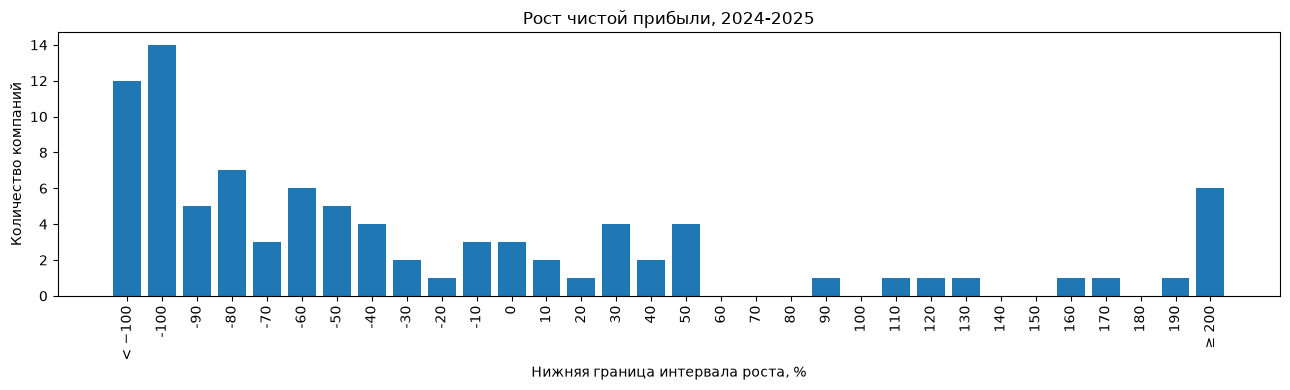

Рост у 29 из 91 компаний с положительной базой, снижение у 62, медиана -55.6%.
В крайних интервалах: 12 и 6 компаний.
2022-2025. Всего пар: 111. База <= 0: 14. Вышли на прибыль: 7.


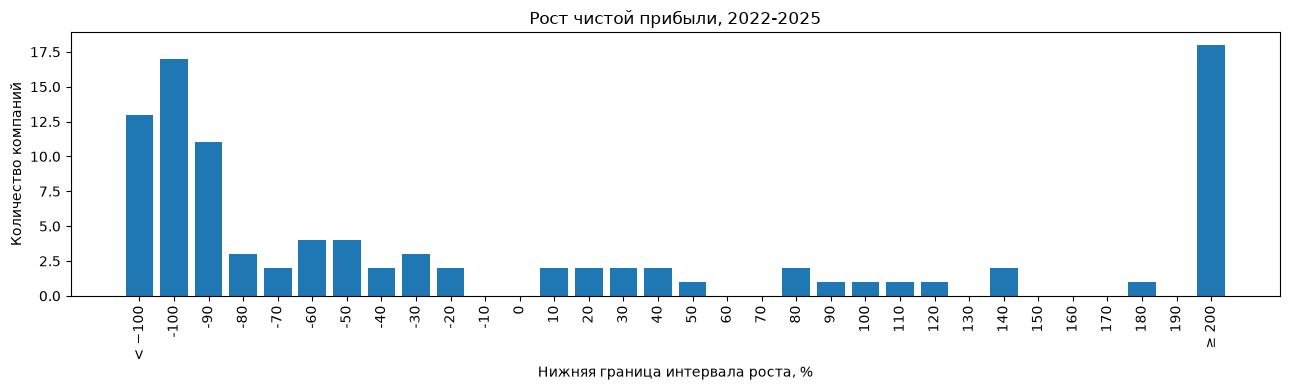

Рост у 36 из 97 компаний с положительной базой, снижение у 61, медиана -53.2%.
В крайних интервалах: 13 и 18 компаний.


In [4]:
profits = finance[['inn', 'year', 'net_profit']].dropna()
for lag in (1, 3):
    prior = profits.rename(columns={'net_profit': 'base_profit'}).assign(year=lambda x: x.year + lag)
    pairs = profits.merge(prior, on=['inn', 'year'], validate='one_to_one')
    if pairs.empty:
        print(f'N={lag}: сопоставимых пар нет.')
        continue
    year = pairs.year.max()
    pair = pairs[pairs.year.eq(year)]
    valid = pair[pair.base_profit.gt(0)].copy()
    excluded = len(pair) - len(valid)
    recovered = (pair.base_profit.le(0) & pair.net_profit.gt(0)).sum()
    print(f'{year - lag}-{year}. Всего пар: {len(pair)}. База <= 0: {excluded}. Вышли на прибыль: {recovered}.')
    if valid.empty:
        continue
    growth = 100 * (valid.net_profit / valid.base_profit - 1)
    integer = growth.round().astype('int64')
    central = integer.between(-100, 199)
    counts = ((integer[central] // 10) * 10).value_counts().reindex(range(-100, 200, 10), fill_value=0)
    labels = ['< −100'] + [str(x) for x in counts.index] + ['≥ 200']
    frequencies = [int(integer.lt(-100).sum()), *counts.tolist(), int(integer.ge(200).sum())]
    fig, ax = plt.subplots(figsize=(13, 4))
    ax.bar(labels, frequencies)
    ax.tick_params(axis='x', rotation=90)
    ax.set(xlabel='Нижняя граница интервала роста, %', ylabel='Количество компаний',
           title=f'Рост чистой прибыли, {year - lag}-{year}')
    fig.tight_layout()
    plt.show()
    print(f'Рост у {growth.gt(0).sum()} из {len(growth)} компаний с положительной базой, '
          f'снижение у {growth.lt(0).sum()}, медиана {growth.median():+.1f}%.')
    print(f'В крайних интервалах: {frequencies[0]} и {frequencies[-1]} компаний.')

## Карта компаний

Для рейтинга беру выручку за 2025 год. В выборке нашлось 105 компаний с выручкой за этот год. Наношу их на карту по населённому пункту регистрации. Если в одном месте несколько компаний, их видно в подсказке. Для восьми населённых пунктов, которых не было в справочнике, использую координаты из OpenStreetMap.

[Справочник населённых пунктов](https://github.com/hflabs/city) | [OpenStreetMap](https://www.openstreetmap.org/copyright)

In [5]:
from html import escape

def normalize(value):
    value = unicodedata.normalize('NFKC', str(value)).casefold().replace('ё', 'е')
    value = re.sub(r'\b(?:город|пос[её]лок|деревня|село|ст|г|п|д|с|область|обл|край|республика|респ|ао)\b', ' ', value)
    return re.sub(r'[^а-яa-z0-9]+', '', value)

city_file = CACHE / 'city.csv'
if not city_file.exists():
    city_response = requests.get('https://raw.githubusercontent.com/hflabs/city/master/city.csv', timeout=20)
    city_response.raise_for_status()
    city_file.write_bytes(city_response.content)
cities = pd.read_csv(city_file, dtype={'kladr_id': str}).dropna(subset=['geo_lat', 'geo_lon'])
cities['region_code'] = cities.kladr_id.str[:2]
locations = {}
for row in cities.itertuples(index=False):
    for name in (row.city, row.settlement, row.region if row.region_code in {'77', '78', '92'} else ''):
        key = normalize(name) if pd.notna(name) else ''
        if key:
            locations.setdefault((row.region_code, key), set()).add((row.geo_lat, row.geo_lon))

extra_locations = pd.read_csv('data/locality_coordinates.csv').set_index(['region', 'district', 'settlement'])

def find_coordinates(row):
    extra_key = (row.region, row.district, row.settlement)
    if extra_key in extra_locations.index:
        point = extra_locations.loc[extra_key]
        return (point.latitude, point.longitude)
    region_code, _, region_name = row.region.partition(' - ')
    names = (row.settlement, row.city)
    if not any(names) and region_code in {'77', '78', '92'}:
        names = (region_name,)
    for name in names:
        points = locations.get((region_code, normalize(name)), set())
        if len(points) == 1:
            return next(iter(points))
    return (float('nan'), float('nan'))

rankable = finance.dropna(subset=['revenue'])
map_year = int(rankable.year.max())
ranking = rankable[rankable.year.eq(map_year)].sort_values(
    ['revenue', 'inn'], ascending=[False, True]
).head(500).reset_index(drop=True)
ranking['rank'] = ranking.index + 1
display(ranking[['rank', 'inn', 'name', 'revenue']].head(10))
map_data = companies.merge(ranking[['inn', 'revenue', 'rank']], on='inn', validate='one_to_one')
map_title = f'Компании по месту регистрации, {map_year}'
map_data[['latitude', 'longitude']] = map_data.apply(find_coordinates, axis=1, result_type='expand')
map_data.sort_values('rank').to_csv(RESULTS / f'revenue_ranking_{map_year}.csv', index=False)
located = map_data.dropna(subset=['latitude', 'longitude'])
print(f'Координаты найдены для {len(located)} из {len(map_data)} компаний.')
if not located.empty:
    groups = located.sort_values('rank').groupby(['latitude', 'longitude'], as_index=False)
    grouped = groups.agg(
        companies=('inn', 'size'),
        region=('region', 'first'),
        ranking=('rank', lambda ranks: ', '.join(ranks.astype(str))),
        names=('name', lambda names: '<br>'.join(escape(name) for name in names)),
    )
    geo = gpd.GeoDataFrame(grouped, geometry=gpd.points_from_xy(grouped.longitude, grouped.latitude), crs='EPSG:4326')
    fig = px.scatter_map(
        geo, lat=geo.geometry.y, lon=geo.geometry.x, size='companies', size_max=30,
        hover_name='region', hover_data={'ranking': True, 'names': True, 'companies': True,
                                        'latitude': False, 'longitude': False},
        labels={'companies': 'Компаний', 'names': 'Компании', 'ranking': 'Места в рейтинге'},
        map_style='carto-positron', center={'lat': 57, 'lon': 61}, zoom=2.4,
        height=550, title=map_title,
    )
    fig.write_html(RESULTS / 'construction_map.html', include_plotlyjs='cdn')
    fig.show(renderer='plotly_mimetype')

,rank,inn,name,revenue
0,1,7724362336,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АРС-...",2784998.0
1,2,5905952421,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""ТНК""",1813603.0
2,3,4501090108,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""ДСМ""",1637351.0
3,4,3128133112,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""ТЕМИ...",1633383.0
4,5,9701193371,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""ГАЛАКС""",1525459.0
5,6,5751005940,"ПУБЛИЧНОЕ АКЦИОНЕРНОЕ ОБЩЕСТВО ""СПЕЦИАЛИЗИРОВА...",1475462.0
6,7,7839411639,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""СТРО...",1378609.0
7,8,1633009588,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""ВИКАРА""",1359131.0
8,9,3460059841,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""АРТ-...",1227490.0
9,10,7717781390,"ОБЩЕСТВО С ОГРАНИЧЕННОЙ ОТВЕТСТВЕННОСТЬЮ ""ЮНИН...",1134037.0


Координаты найдены для 105 из 105 компаний.


## Вывод

В 2025 году прибыль снизилась у 62 из 91 компании с положительной прибылью в 2024 году. Медианное изменение за год составило -55,6%. По сравнению с 2022 годом оно составило -53,2%.

EBITA получилось рассчитать по 22 отчётам 10 компаний. За 2025 год показатель был положительным у 6 из 9 компаний с доступными данными. У пяти компаний с данными за оба года медианное изменение маржи EBITA за 2024-2025 годы составило -1,94 п. п.

У многих компаний в выборке прибыль снизилась. Судить о перспективности всей отрасли по EBITA сложно, потому что в большинстве отчётов не хватает данных для расчёта. На карту попали все 105 компаний из рейтинга по выручке.